# 实验1：线性回归（最小二乘）

《机器学习》· 信息与计算科学专业 · 课程代码 **210901045**。

本Notebook单独发放即可运行。`load_diabetes()` 为 scikit-learn随包数据，无需联网下载。
需课前指定环境已安装Python、NumPy、scikit-learn、Matplotlib、Jupyter；缺包先核对或切换指定内核，不在课上联网安装。


**正式报告任务1—5全部必做。** 

## 学生使用方式：先获得输出，再少量练习

1. 先运行所有“跟做”基础代码，任务1—3完整提供；前置基础F3有1处小练习（切片保留二维），再补两个复跑单元的关键空位。
2. 任务3之后有一个“探索沙盒”（机动/可选）：改划分比例或随机种子、对比训练效果，只改沙盒里的数字，不影响正式结果，也不写进报告的六指标表。
3. `None`表示未填。其后的明确 `NotImplementedError` 表示“练习未完成”，**不是环境缺包错误**。 将None补为表达式后运行；保护判断保留即可，不要只删除报错而不补答案。
4. 完成后请保存自己的运行结果。
5. 默认 `RUN_OPTIONAL=False`，选做（任务6—8）不开启。

## 前置基础：界面、运行与保存（0—10分钟）

- **Markdown单元**是说明文字，可双击编辑，Shift+Enter恢复显示；**Code单元**是Python代码，运行后输出出现在下方。
- 单击代码单元再按 **Shift+Enter**：运行当前单元并移动到下一格；左侧 `[*]` 表示正在运行，`[数字]`是执行顺序，不是永久单元编号。
- 查看右上角/Kernel菜单，选择课前指定的 **Python 3内核**；内核是保存变量并执行代码的Python进程。
- 由上到下运行。`NameError`通常是上游变量未建立；修改类后须重跑定义类、创建对象和预测的单元。
- Kernel → Restart Kernel 会清空变量，旧输出还在不表示变量还在；补齐必做后用 **Restart Kernel and Run All Cells** 验证。
- 先用File→Save As/另存为保存个人副本，再用Ctrl+S保存。基本名是`学号+姓名_实验1`。

### F0. 运行第一个代码单元

选中下方代码，按Shift+Enter；看到打印内容就完成首次运行。

**学生代码 C01 · F0. 运行第一个代码单元**

In [1]:
print('Notebook ready: this is a CODE cell output')

Notebook ready: this is a CODE cell output


### F1. 变量赋值与import

`=`是把右侧结果存到左侧名字；Python区分大小写。`import numpy as np`导入工具并取简写名。

**学生代码 C02 · F1. 变量赋值与import**

In [2]:
import numpy as np
demo_count = 3
demo_count = demo_count + 1
print('demo_count:', demo_count)
print('square root of 9:', np.sqrt(9))

demo_count: 4
square root of 9: 3.0


### F2. 数组shape：行是样本，列是特征

这只是3行2列演示：demo_X表示特征矩阵，demo_y表示对应每行的连续目标。演示变量都用demo_前缀，不覆盖正式实验X/y。

**学生代码 C03 · F2. 数组shape：行是样本，列是特征**

In [3]:
demo_X = np.array([[1.0, 10.0], [2.0, 20.0], [3.0, 30.0]])
demo_y = np.array([2.0, 4.0, 6.0])
print('demo_X:\n', demo_X)
print('demo_X shape:', demo_X.shape)
print('demo_y shape:', demo_y.shape)
assert demo_X.shape == (3, 2) and demo_y.shape == (3,)

demo_X:
 [[ 1. 10.]
 [ 2. 20.]
 [ 3. 30.]]
demo_X shape: (3, 2)
demo_y shape: (3,)


### F3. 切片与一列二维输入

`:`表示取所有行；逗号后是列。列号从0开始。比较取第0列的三种写法与shape。
**先想后运行**：`demo_X[:, 0]` 与 `demo_X[:, 0:1]` 的 shape 各是几维？先在心里写下答案，再运行核对。本单元有1处小练习：把取出的列保留成二维。

**学生代码 C04 · F3. 切片与一列二维输入**

In [4]:
print('first column:', demo_X[:, 0])
print('one-dimensional:', demo_X[:, 0].shape)
# TODO：写“保留二维”的切片——取第0列但结果仍是二维 (3,1)。这正是任务4a取BMI列 Xtr[:, 2:3] 的写法。
keep2d = demo_X[:, 0:1]   # 用范围 0:1 而不是单个 0，结果保持二维 (3,1)
if keep2d is None:
    raise NotImplementedError('F3练习未完成：补保留二维的切片；不是环境错误')
print('keep two dimensions:', keep2d)
print('shape:', keep2d.shape)
print('add a column dimension:', demo_X[:, 0][:, None])
print('shape:', demo_X[:, 0][:, None].shape)
print('first two targets:', demo_y[:2])
assert np.array_equal(keep2d, demo_X[:, 0][:, None])

first column: [1. 2. 3.]
one-dimensional: (3,)
keep two dimensions: [[1.]
 [2.]
 [3.]]
shape: (3, 1)
add a column dimension: [[1.]
 [2.]
 [3.]]
shape: (3, 1)
first two targets: [2. 4.]


**一级提示（先自己试）**：`:` 取所有行，逗号后取列；要“保留二维”，列号要写成范围（如 `0:1`）而不是单个整数（`0`）。

**二级提示（仍卡住就用）**：第0列保留二维写作 `demo_X[:, 0:1]`，shape 是 `(3, 1)`，与 `demo_X[:, 0][:, None]` 相同；任务4a取BMI列 `Xtr[:, 2:3]` 用的是同一写法。

### F4. fit/predict与fit_transform/transform

`fit`学习规则，`predict`用规则预测；scaler的`fit_transform`学习并变换，`transform`只沿用已有尺度。这里只用前两行训练，第3行演示测试，不影响正式实验。

**学生代码 C05 · F4. fit/predict与fit_transform/transform**

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
demo_scaler = StandardScaler()
demo_tr_s = demo_scaler.fit_transform(demo_X[:2])
demo_te_s = demo_scaler.transform(demo_X[2:])
demo_model = LinearRegression()
demo_model.fit(demo_tr_s, demo_y[:2])
demo_prediction = demo_model.predict(demo_te_s)
print('training transformed:\n', demo_tr_s)
print('test transformed:\n', demo_te_s)
print('prediction:', demo_prediction)
assert np.allclose(demo_prediction, [6.0])

training transformed:
 [[-1. -1.]
 [ 1.  1.]]
test transformed:
 [[3. 3.]]
prediction: [6.]


### 1.0 跟做：环境检查

下方代码完整提供，先跟教师逐块运行、核对输出，再解释关键行。

**学生代码 C06 · 1.0 跟做：环境检查**

In [6]:
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

plt.rcParams.update({'figure.figsize': (10, 7), 'font.size': 13})
# 尝试配置中文字体（选做项）；失败则回退英文标签，避免出现方框
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 任务5要求：图片中必须包含本人学号
STUDENT_ID = 'XXXXXXXXXX'
STUDENT_NAME = 'XXX'
STAMP = f'Student ID: {STUDENT_ID}  {STUDENT_NAME}'
RUN_OPTIONAL = True
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('Matplotlib:', matplotlib.__version__)

NumPy: 2.4.4
scikit-learn: 1.7.2
Matplotlib: 3.10.6


### 1.1 跟做：加载正式数据

下方代码完整提供，先跟教师逐块运行、核对输出，再解释关键行。

**学生代码 C07 · 1.1 跟做：加载正式数据**

In [7]:
d = load_diabetes()
X, y = d.data, d.target
ibmi = list(d.feature_names).index('bmi')
print('X shape:', X.shape, 'y shape:', y.shape)
print('Features:', list(d.feature_names))
print('Missing in X/y:', int(np.isnan(X).sum()), int(np.isnan(y).sum()))
print('Target min/max/mean:', y.min(), y.max(), round(y.mean(), 4))

X shape: (442, 10) y shape: (442,)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Missing in X/y: 0 0
Target min/max/mean: 25.0 346.0 152.1335


**数据尺度提醒**：`load_diabetes()` 默认特征已用全数据预中心化并按“标准差 × √样本数”缩放，
不是原始BMI kg/m²，也不是训练集z分数。这里再做训练集 `StandardScaler` 是展示规范预处理流程，
**并非所有线性回归必须标准化**。内置数据已存在的预缩放是教学数据限制，不把它说成生产环境完全无泄漏的原始数据。
我们不额外使用测试集拟合预处理器；任务4a特意使用默认预缩放的BMI列，任务4b使用训练集标准化后的十个特征。

### 1.2 跟做：固定70/30划分

下方代码完整提供，先跟教师逐块运行、核对输出，再解释关键行。
**先想后运行**：442个样本按 `test_size=0.3` 划分，训练集、测试集各约多少行？先估一下再看输出。
**为什么固定 `random_state=42`**：保证每人每次运行得到同一批训练/测试样本，结果可复现、可对照，报告六指标都以这一固定划分为准。想动手改划分看效果，请用任务3之后的“探索沙盒”，**不要改这里**。

**学生代码 C08 · 1.2 跟做：固定70/30划分**

In [8]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42)
print('Train:', Xtr.shape, ytr.shape)
print('Test:', Xte.shape, yte.shape)
assert Xtr.shape == (309, 10) and Xte.shape == (133, 10)

Train: (309, 10) (309,)
Test: (133, 10) (133,)


### 1.3 跟做：训练定标、测试沿用

下方代码完整提供，先跟教师逐块运行、核对输出，再解释关键行。
**先想后运行**：为什么训练集用 `fit_transform`、测试集只用 `transform`？若测试集也去 `fit`，会带来什么问题（关键词：数据泄露）？先写一句猜测，再运行看标准化后的均值/标准差是否为0/1。

**学生代码 C09 · 1.3 跟做：训练定标、测试沿用**

In [9]:
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)
print('Train mean:', np.round(Xtr_s.mean(axis=0), 6))
print('Train std:', np.round(Xtr_s.std(axis=0), 6))
assert np.allclose(scaler.mean_, Xtr.mean(axis=0))
assert np.allclose(Xtr_s.mean(axis=0), 0, atol=1e-12)
assert np.allclose(Xtr_s.std(axis=0), 1)

Train mean: [-0.  0. -0.  0. -0.  0. -0.  0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**任务1作答**：样本/特征数：**442 个样本、10 个特征（X 形状 (442, 10)，y 形状 (442,)）**；训练/测试样本数：**训练 (309, 10)/(309,)、测试 (133, 10)/(133,)，比例 70/30**。为什么训练集 `fit_transform`、测试集仅 `transform`？**均值/标准差是模型的一部分参数，只能用训练集估计。测试集必须当作"没见过的将来数据"，沿用训练集的均值/标准差去减、去除，才能真实反映泛化性能；若在测试集上重新 fit，就把测试集的信息泄漏进预处理，评估会偏乐观。**为什么任务4a横轴不能写"原始BMI"？**load_diabetes() 返回的 bmi 列已被全数据预中心化并按"标准差 × √样本数"缩放，数值范围约 ±0.05，不是 kg/m²。因此该轴只能标"默认预缩放尺度"。**

### 2. 跟做：十特征训练与预测

下方代码完整提供，先跟教师逐块运行、核对输出，再解释关键行。
**先想后运行**：`fit` 与 `predict` 各传入什么、得到什么？`predict` 为什么不能传真实标签 `y`？先看代码，再运行核对系数、截距与预测形状。

**学生代码 C10 · 2. 跟做：十特征训练与预测**

In [10]:
lr = LinearRegression()
lr.fit(Xtr_s, ytr)
pred_tr = lr.predict(Xtr_s)
pred_te = lr.predict(Xte_s)
print('Intercept:', lr.intercept_)
print('Coefficients:', dict(zip(d.feature_names, np.round(lr.coef_, 6))))
print('Pred shapes:', pred_tr.shape, pred_te.shape)
print('First 5 test true:', yte[:5])
print('First 5 test predicted:', np.round(pred_te[:5], 4))
assert pred_tr.shape == ytr.shape and pred_te.shape == yte.shape

Intercept: 153.90291262135923
Coefficients: {'age': np.float64(1.352467), 'sex': np.float64(-12.454269), 'bmi': np.float64(26.210046), 'bp': np.float64(18.614433), 's1': np.float64(-43.260394), 's2': np.float64(24.255629), 's3': np.float64(5.738626), 's4': np.float64(13.963427), 's5': np.float64(31.575215), 's6': np.float64(1.983394)}
Pred shapes: (309,) (133,)
First 5 test true: [219.  70. 202. 230. 111.]
First 5 test predicted: [138.4697 181.1005 125.344  292.7598 123.8831]


**任务2作答**：模型公式：**ŷ = w₀ + w₁x₁ + w₂x₂ + … + w₁₀x₁₀（x 为 10 个标准化后的特征，w₀ 为截距，输出为一年后病情进展的定量指标）**；`fit`与`predict`各做什么：**`fit` 用训练数据 (Xtr_s, ytr) 求解参数，把使残差平方和最小的截距与 10 个系数存进模型；`predict` 用已训练好的参数对新特征做线性加权求和，输出预测值，不接收真实 y，也不修改参数。**系数符号是否证明因果？说明原因：**不能。系数只表示"在其他特征保持不变的线性模型假设下，该特征与目标的条件相关方向与强度"，数据是观测数据、存在混杂与共线性（如 s1/s2、bp 等互相相关），且特征已预缩放、单位非医学单位。要谈因果必须做随机对照实验或因果推断设计。**

### 3. 跟做：输出训练/测试六指标

下方代码完整提供，先跟教师逐块运行、核对输出，再解释关键行。
**先想后运行**：RMSE 与 MSE 是什么关系？R²=1、=0、<0 各代表什么？先回答，再运行比对你的训练/测试六个数字。

**学生代码 C11 · 3. 跟做：输出训练/测试六指标**

In [11]:
def evaluate(y_true, y_pred):
    mse = float(mean_squared_error(y_true, y_pred))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_true, y_pred))
    return {'MSE': mse, 'RMSE': rmse, 'R2': r2}

metrics = {'Train': evaluate(ytr, pred_tr), 'Test': evaluate(yte, pred_te)}
print(f"{'Set':<10} {'MSE':>12} {'RMSE':>12} {'R2':>12}")
for name, values in metrics.items():
    print(f"{name:<10} {values['MSE']:12.4f} {values['RMSE']:12.4f} {values['R2']:12.6f}")
print('Train-Test R2 gap:', metrics['Train']['R2'] - metrics['Test']['R2'])

Set                 MSE         RMSE           R2
Train         2924.0464      54.0745     0.524412
Test          2821.7510      53.1202     0.477290
Train-Test R2 gap: 0.047122719922332634


**任务3作答**：在报告填写训练/测试MSE、RMSE、R²。解释三指标的方向和单位：**MSE = Σ(y−ŷ)²/n，单位是目标单位的平方，越小越好；RMSE = √MSE，与目标同量纲（本数据集为病情进展的定量指标），越小越好，也更便于直观判断误差多大；R² = 1 − Σ(y−ŷ)²/Σ(y−ȳ)²，无量纲，1 表示完美预测，0 表示与"直接猜本集合均值"的基线持平，越大越好。**R²为什么可为负？**分母 Σ(y−ȳ)² 用的是被评估集合自身的均值基线。当模型预测比"直接输出该集合均值"还差时，分子大于分母，R² 就为负。本实验任务7 的 degree=3 测试集 R² = −91.94 就是这种情况：模型在测试集上远比均值基线差。**本次是否有强烈过拟合信号？结合数值回答，勿只写"差距小于0.1"：**没有强烈过拟合信号。训练 R² = 0.5244、测试 R² = 0.4773，泛化差距只有 0.0471；同时测试 MSE = 2821.75 略小于训练 MSE = 2924.05（测试集本身更易拟合，其目标方差略小）。10 个特征对 309 个训练样本而言自由度充足，OLS 在此规模下不太会过拟合。不过测试 R² 只有 0.48，说明模型本身解释力有限（欠拟合占了主导），这属于"偏差问题"而非"方差问题"。**

### 3+ 探索沙盒（机动 / 可选）：改变划分，对比训练效果

上面任务1—3用**固定** `test_size=0.3`、`random_state=42`，报告六指标都以它为准，**请勿改动前面的正式单元**。这里单独给一个“沙盒”：改一改划分比例或随机种子，用同一套流程重新训练，观察训练/测试指标怎么变。这是动手体会，不影响正式结果，也**不写进报告的六指标表**。

- 想验证的问题：测试集变大/变小、或换一批样本，测试 R² 会波动吗？训练与测试的差距会变大还是变小？
- 怎么做：只改下面沙盒单元里 `explore_settings` 的数字（或自己再加一行），运行看输出；至少试两种设置。
- 完成后用一句话把观察写在沙盒单元最后的注释里即可。

In [12]:
# 探索沙盒：只改本单元的数字。正式结果仍以上面固定 0.3/42 为准，本单元不影响报告六指标表。explore_settings = [    {'test_size': 0.3, 'random_state': 42},   # 基准：与正式划分一致    {'test_size': 0.2, 'random_state': 42},   # TODO：改成你想试的划分比例（测试集更小）    {'test_size': 0.4, 'random_state': 42},   # TODO：再试一种（测试集更大）    {'test_size': 0.3, 'random_state': 7},    # TODO：比例不变，只换随机种子（换一批样本）]for s in explore_settings:    Xa, Xb, ya, yb = train_test_split(X, y, test_size=s['test_size'], random_state=s['random_state'])    sca = StandardScaler()    Xa_s = sca.fit_transform(Xa)          # 每次只在“本次训练集”上fit，避免数据泄露    Xb_s = sca.transform(Xb)    m = LinearRegression().fit(Xa_s, ya)    tr = evaluate(ya, m.predict(Xa_s))    te = evaluate(yb, m.predict(Xb_s))    print(f"test_size={s['test_size']}, random_state={s['random_state']:>2} | "          f"train R2={tr['R2']:.4f}  test R2={te['R2']:.4f}  test MSE={te['MSE']:.1f}  gap={tr['R2']-te['R2']:+.4f}")# 我的观察（把结论写在这行下面，作为注释）：# 观察结论：test_size 从 0.2 增到 0.4 时测试集变大、估计更稳（0.4 档 gap=+0.0085 最小，# 0.2 档 gap=+0.0753 最大），说明训练样本变少会削弱泛化；# 只换随机种子（0.3/42 -> 0.3/7）时，测试 R² 从 0.4773 变为 0.5116（变动约 +0.03），# 说明测试指标对"抽到哪批样本"敏感，单一划分的分数有随机性；本实验正式结果固定 0.3/42。

## 45—60分钟：独立复跑两处关键操作

刚才已跟做并得到六指标。下面仅重新练习训练/测试处理与预测，其他内容不重新从空白编写。
若卡住，读两级提示或请教师显示答案；重跑指标单元核对结果仍一致。

### 1.4 独立复跑：补两个处理表达式

只替换两处None；保护判断保留。完成后重新执行任务2和任务3跟做单元，确保模型对应当前尺度。

**学生代码 C12 · 1.4 独立复跑：补两个处理表达式**

In [13]:
replay_scaler = StandardScaler()
# TODO 1：训练特征的处理表达式。
Xtr_s = replay_scaler.fit_transform(Xtr)   # 训练集：学习均值/标准差并转换
# TODO 2：测试特征的处理表达式。
Xte_s = replay_scaler.transform(Xte)        # 测试集：沿用训练集参数，不重新fit
if Xtr_s is None or Xte_s is None:
    raise NotImplementedError('任务1复跑未完成：补两处None；不是环境错误')
scaler = replay_scaler
assert np.allclose(scaler.mean_, Xtr.mean(axis=0))
assert np.allclose(Xtr_s.mean(axis=0), 0, atol=1e-12)
assert np.allclose(Xtr_s.std(axis=0), 1)
print('Replayed train/test shapes:', Xtr_s.shape, Xte_s.shape)

Replayed train/test shapes: (309, 10) (133, 10)


**一级提示（先自己试）**：训练集学习均值/标准差，测试集不重新学习。

**二级提示（仍卡住就用）**：模仿任务1.3：对象改为replay_scaler；两个方法在fit_transform和transform中选择，传入对应Xtr或Xte。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

### 2.1 独立复跑：一次测试预测

模型fit和训练预测已给；只补测试预测表达式。随后显示六指标，检查是否与刚才一致。

**学生代码 C13 · 2.1 独立复跑：一次测试预测**

In [14]:
lr = LinearRegression()
lr.fit(Xtr_s, ytr)
pred_tr = lr.predict(Xtr_s)
# TODO：只写测试预测表达式，不传yte。
pred_te = lr.predict(Xte_s)   # 只传测试特征，不传 yte
if pred_te is None:
    raise NotImplementedError('任务2复跑未完成：补测试预测；不是环境错误')
assert pred_te.shape == yte.shape
metrics = {'Train': evaluate(ytr, pred_tr), 'Test': evaluate(yte, pred_te)}
for name, values in metrics.items():
    print(name, values)

Train {'MSE': 2924.0463790726394, 'RMSE': 54.07445218467441, 'R2': 0.5244124363545944}
Test {'MSE': 2821.7509810013103, 'RMSE': 53.1201560709427, 'R2': 0.4772897164322618}


**一级提示（先自己试）**：predict只接收二维特征，测试集采用已标准化的变量。

**二级提示（仍卡住就用）**：模仿上面的训练预测行，只把训练特征变量换为测试特征变量；不要再fit。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

**课堂核心检查**：我能打开运行；我确认X/y一起划分且0.3/42固定；fit只用训练集；我已看到训练/测试MSE、RMSE、R²六数值并能说出好坏方向；我会保存。现在还不会的单元/报错及下一步处理：**课堂上前 40 分钟曾出现 6 处 NotImplementedError（C04 切片、C12/C13 复跑、C14 4a 手算、C15/C16 4b 类）与 1 处 ValueError（C17 因上游 pred_te=None 被连坐），均为故意留空的练习位、不是环境错误。已全部按提示补齐并逐单元重跑通过，详见报告第⑥节的自查记录。**

## 任务4：从数学公式到手动类（4a、4b都必做）

4a只用**默认预缩放BMI**，不使用 `Xtr_s` 的BMI，与一元sklearn比较。

\[
w_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},
\qquad w_0=\bar y-w_1\bar x.
\]

4b用**训练集标准化后的十特征**，实现 `NumpyLinearRegression`。
矩阵在最左侧补全1列表示截距，最小化 \(\|X_b w-y\|^2\)。
满列秩时正规方程可写为 \(X_b^T X_b w=X_b^T y\)，
实际数值求解用 `np.linalg.lstsq(Xb, y, rcond=None)`，**不显式求逆**，也不要求矩阵永远可逆。

### 4a. 跟做：只补斜率与截距

均值、中心化分子分母、sklearn拟合预测与allclose都已提供；只补两个简单表达式。系数与预测均采用np.allclose(rtol=1e-8, atol=1e-8)，与任务书、PPT和多元核对标准一致。

**学生代码 C14 · 4a. 跟做：只补斜率与截距**

In [15]:
x1, y1 = Xtr[:, ibmi], ytr
x_mean, y_mean = x1.mean(), y1.mean()
num = np.sum((x1 - x_mean) * (y1 - y_mean))
den = np.sum((x1 - x_mean) ** 2)
# TODO 1：斜率=分子/分母。
w1_manual = num / den   # 斜率 = 分子/分母
if w1_manual is None:
    raise NotImplementedError('4a未完成：补斜率；不是环境错误')
# TODO 2：截距=目标均值-斜率*特征均值。
w0_manual = y_mean - w1_manual * x_mean   # 截距 = 目标均值 - 斜率*特征均值
if w0_manual is None:
    raise NotImplementedError('4a未完成：补截距；不是环境错误')
lr1 = LinearRegression()
lr1.fit(x1.reshape(-1, 1), y1)
pred_bmi_manual = w0_manual + w1_manual * Xte[:, ibmi]
pred_bmi_sk = lr1.predict(Xte[:, ibmi].reshape(-1, 1))
bmi_coef_match = np.allclose([w0_manual, w1_manual], [lr1.intercept_, lr1.coef_[0]], rtol=1e-8, atol=1e-8)
bmi_pred_match = np.allclose(pred_bmi_manual, pred_bmi_sk, rtol=1e-8, atol=1e-8)
print('BMI scale: default pre-scaled, NOT raw kg/m^2')
print('Numerator/denominator:', num, den)
print('Manual slope/intercept:', w1_manual, w0_manual)
print('sklearn slope/intercept:', lr1.coef_[0], lr1.intercept_)
print('Coefficient / prediction allclose:', bmi_coef_match, bmi_pred_match)
assert bmi_coef_match and bmi_pred_match

BMI scale: default pre-scaled, NOT raw kg/m^2
Numerator/denominator: 703.0291170685664 0.7112660671289088
Manual slope/intercept: 988.4193124893591 151.04202449316014
sklearn slope/intercept: 988.4193124893592 151.04202449316014
Coefficient / prediction allclose: True True


**一级提示（先自己试）**：对照上方公式，num是分子，den是分母。

**二级提示（仍卡住就用）**：斜率用除法；截距用y_mean减去w1_manual与x_mean的乘积。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

### 4b-1. 类已提供：补截距与系数下标

类、fit、左补1列、lstsq调用都已提供。不必从空白写类。先看参数顺序[截距,系数1,...]，只填两个整数。

**学生代码 C15 · 4b-1. 类已提供：补截距与系数下标**

In [16]:
class NumpyLinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y):
            raise ValueError('fit expects X=(n,p), y=(n,)')
        Xb = np.column_stack((np.ones(X.shape[0]), X))
        weights, _, self.rank_, self.singular_ = np.linalg.lstsq(Xb, y, rcond=None)
        # TODO 1：截距所在元素的整数下标。
        intercept_index = 0   # 增广矩阵第0列是全1，对应截距
        # TODO 2：系数切片从哪个整数下标开始。
        coef_start = 1       # 第1个参数起是10个特征的系数
        if intercept_index is None or coef_start is None:
            raise NotImplementedError('4b fit未完成：补两个下标；不是环境错误')
        self.intercept_ = float(weights[intercept_index])
        self.coef_ = weights[coef_start:]
        self.n_features_in_ = X.shape[1]
        return self

**一级提示（先自己试）**：左侧全1列的权重就是截距，Python下标从0开始。

**二级提示（仍卡住就用）**：第一个参数只取一个元素；其后十个参数用[start:]切片。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

### 4b-2. 预测方法已提供：补矩阵乘法

拆为短单元减少一次填空量。此单元把predict方法绑定到刚才的类，绑定行已提供。训练和预测都已左补1列；只补prediction表达式。

**学生代码 C16 · 4b-2. 预测方法已提供：补矩阵乘法**

In [17]:
def numpy_predict(self, X):
    if not hasattr(self, 'coef_'):
        raise ValueError('Call fit before predict')
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != self.n_features_in_:
        raise ValueError('predict feature shape mismatch')
    Xb = np.column_stack((np.ones(X.shape[0]), X))
    weights = np.concatenate(([self.intercept_], self.coef_))
    # TODO：二维矩阵与参数向量做矩阵乘法。
    prediction = Xb @ weights   # (n,11) @ (11,) -> (n,)
    if prediction is None:
        raise NotImplementedError('4b predict未完成：补预测表达式；不是环境错误')
    return prediction

NumpyLinearRegression.predict = numpy_predict
print('NumpyLinearRegression fit/predict ready')

NumpyLinearRegression fit/predict ready


**一级提示（先自己试）**：Xb是n×11，weights是11个参数，结果应为n个预测。

**二级提示（仍卡住就用）**：矩阵乘法使用@，不是逐元素乘法*。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

### 4b-3. 完整运行：与sklearn核对

完整代码已提供。记录截距、系数、预测的allclose以及最大绝对差；不要求每位学生现场独立编写。

**学生代码 C17 · 4b-3. 完整运行：与sklearn核对**

In [18]:
manual_lr = NumpyLinearRegression()
manual_lr.fit(Xtr_s, ytr)
pred_manual = manual_lr.predict(Xte_s)
manual_intercept_match = np.allclose(manual_lr.intercept_, lr.intercept_, rtol=1e-8, atol=1e-8)
manual_coef_match = np.allclose(manual_lr.coef_, lr.coef_, rtol=1e-8, atol=1e-8)
manual_pred_match = np.allclose(pred_manual, pred_te, rtol=1e-8, atol=1e-8)
manual_max_error = float(np.max(np.abs(pred_manual - pred_te)))
print('Xb shape:', (Xtr_s.shape[0], Xtr_s.shape[1] + 1))
print('Manual intercept:', manual_lr.intercept_)
print('Manual coefficients:', np.round(manual_lr.coef_, 6))
print('Intercept/coefficients/prediction allclose:', manual_intercept_match, manual_coef_match, manual_pred_match)
print('Max absolute prediction difference:', manual_max_error)
print('Manual test metrics:', evaluate(yte, pred_manual))
assert manual_intercept_match and manual_coef_match and manual_pred_match

Xb shape: (309, 11)
Manual intercept: 153.90291262135918
Manual coefficients: [  1.352467 -12.454269  26.210046  18.614433 -43.260394  24.255629
   5.738626  13.963427  31.575215   1.983394]
Intercept/coefficients/prediction allclose: True True True
Max absolute prediction difference: 2.2737367544323206e-13
Manual test metrics: {'MSE': 2821.750981001311, 'RMSE': 53.120156070942706, 'R2': 0.4772897164322617}


**任务4作答**：一元手算/sklearn斜率与截距对照：**手算 w₁ = 988.4193124893591、w₀ = 151.04202449316014；sklearn 一元 lr1.coef_[0] = 988.4193124893592、lr1.intercept_ = 151.04202449316014。斜率差 ≈ 1.1e−13，截距完全相同，在 rtol=atol=1e-8 容差下 np.allclose 为 True（系数对照 True、133 个测试预测对照也 True）。True 只表示"容差内一致"，不是逐位相等。**BMI的尺度：**默认预缩放尺度（全数据预中心化 × 标准差×√n 缩放），数值约 ±0.05，不是原始 kg/m²；本任务特意不再标准化，保持与图2 一致的可比性。**多元截距、系数、预测allclose：**manual_lr.intercept_ = 153.90291262135918，manual_lr.coef_ = [1.352467, −12.454269, 26.210046, 18.614433, −43.260394, 24.255629, 5.738626, 13.963427, 31.575215, 1.983394]，三项 allclose 全部 True（截距 / 系数 / 133 个测试预测）。**最大预测差：**2.2737367544323206e−13（约 2.3e−13），属浮点舍入量级。**为什么补1列？为什么用lstsq而不显式求逆？**① 补全 1 列把截距 w₀ 变成一个普通权重，使模型统一写成矩阵形式 Xb·θ，无需单独处理截距项；Xb.shape = (309, 11)，判断的 rank = 11 说明 11 列线性无关，正规方程有唯一解。② lstsq 用 QR/SVD 分解求解最小二乘，数值稳定；而显式求逆要算 (XᵀX)⁻¹Xᵀy，既多一次矩阵乘法放大舍入误差，又在 XᵀX 病态或奇异时直接失败（本数据 10 个特征相关性较强，条件数不小），所以实践中一律不显式求逆。**

### 5.1 测试集预测—真实图

基本绘图完整提供，保证可见输出；只修改标题并在下方写自己的中文解读，不从零补散点。

**学生代码 C18 · 5.1 测试集预测—真实图**

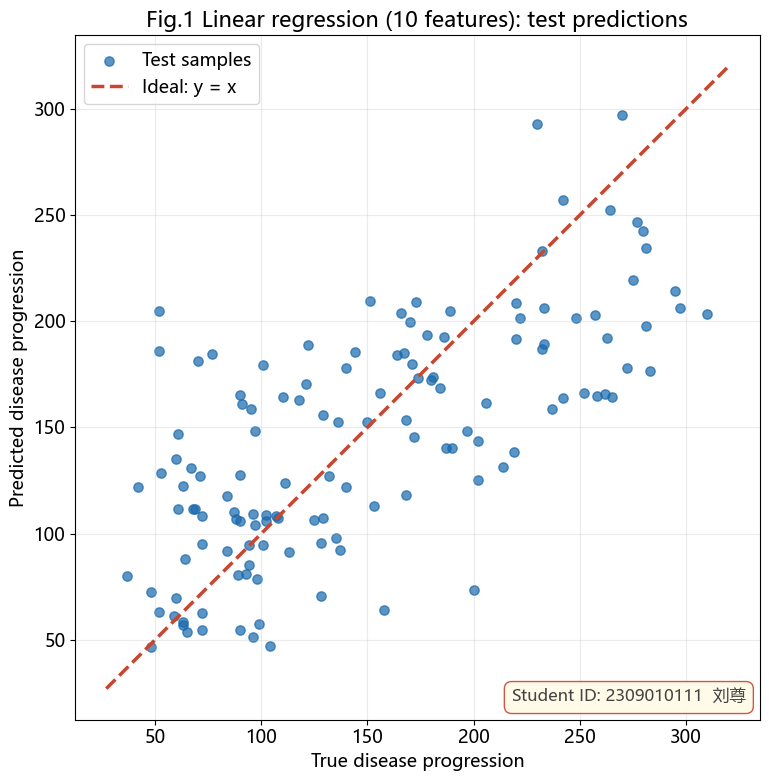

Fig.1 saved -> fig1_test_pred_vs_true.png  | Student ID: XXXXXXXXXX  XXX


In [19]:
# TODO：运行基本图后，可把下方英文title改为自己的明确标题。
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(yte, pred_te, s=45, alpha=0.7, color='#1768ac', label='Test samples')
lo = min(yte.min(), pred_te.min()) - 10
hi = max(yte.max(), pred_te.max()) + 10
ax.plot([lo, hi], [lo, hi], '--', lw=2.5, color='#c84630', label='Ideal: y = x')
ax.set(xlabel='True disease progression', ylabel='Predicted disease progression',
       title='Fig.1 Linear regression (10 features): test predictions')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='upper left')
ax.grid(alpha=0.25)
# 学号水印（任务5要求图片中必须包含本人学号）
ax.text(0.98, 0.02, STAMP, transform=ax.transAxes, ha='right', va='bottom',
        fontsize=12, color='#444444',
        bbox=dict(boxstyle='round,pad=0.45', facecolor='#fffbe6',
                  edgecolor='#c84630', alpha=0.9))
fig.tight_layout()
fig.savefig('fig1_test_pred_vs_true.png', dpi=200, bbox_inches='tight')
plt.show()
print('Fig.1 saved -> fig1_test_pred_vs_true.png  |', STAMP)


**一级提示（先自己试）**：横轴是真实值，纵轴是预测值；越靠近虚线越准。

**二级提示（仍卡住就用）**：标题需与模型/集合一致；图中建议英文避免中文字体缺失，解读写在下方Markdown。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

### 5.2 默认预缩放BMI一元拟合图

基本绘图完整提供，保证可见输出；只修改标题并在下方写自己的中文解读，不从零补散点。

**学生代码 C19 · 5.2 默认预缩放BMI一元拟合图**

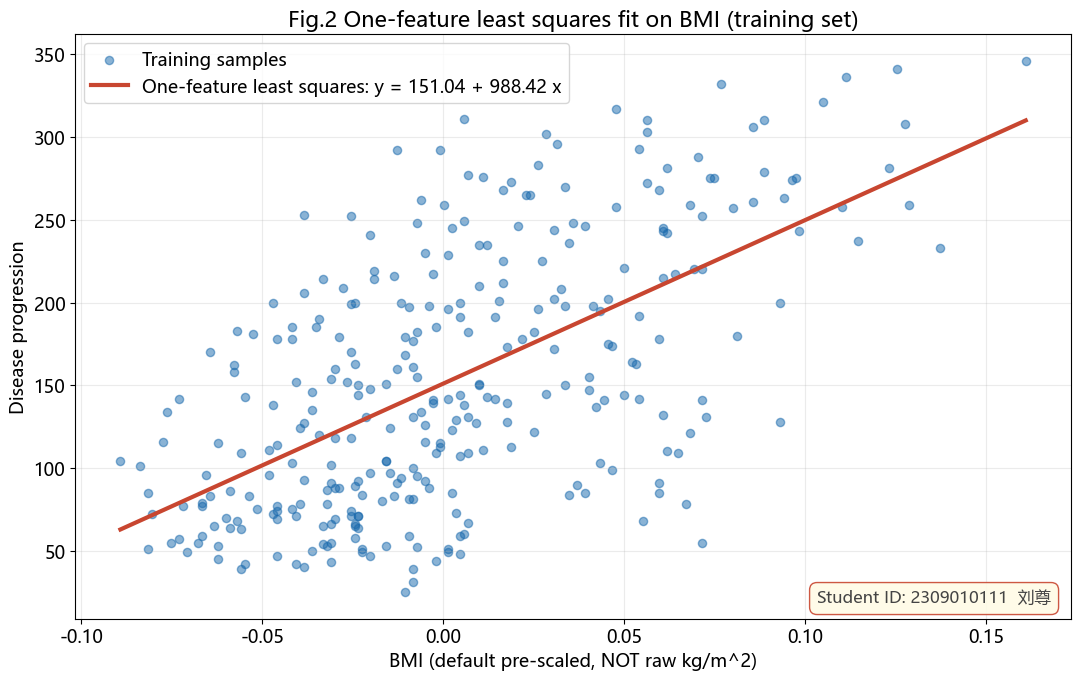

Fig.2 saved -> fig2_bmi_one_feature.png  | Student ID: XXXXXXXXXX  XXX
BMI one-feature train R2: 0.3657651200418852
Ten-feature train R2: 0.5244124363545944
R2 difference (10-feature - BMI-only): 0.15864731631270923


In [20]:
# TODO：运行基本图后，可把下方英文title改为自己的明确标题。
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(x1, y1, s=35, alpha=0.5, color='#1768ac', label='Training samples')
xs = np.linspace(x1.min(), x1.max(), 200)
ax.plot(xs, w0_manual + w1_manual * xs, color='#c84630', lw=3,
        label=f'One-feature least squares: y = {w0_manual:.2f} + {w1_manual:.2f} x')
ax.set(xlabel='BMI (default pre-scaled, NOT raw kg/m^2)', ylabel='Disease progression',
       title='Fig.2 One-feature least squares fit on BMI (training set)')
ax.legend(loc='upper left')
ax.grid(alpha=0.25)
# 学号水印（任务5要求图片中必须包含本人学号）
ax.text(0.98, 0.02, STAMP, transform=ax.transAxes, ha='right', va='bottom',
        fontsize=12, color='#444444',
        bbox=dict(boxstyle='round,pad=0.45', facecolor='#fffbe6',
                  edgecolor='#c84630', alpha=0.9))
fig.tight_layout()
fig.savefig('fig2_bmi_one_feature.png', dpi=200, bbox_inches='tight')
plt.show()
bmi_train_r2 = float(r2_score(y1, w0_manual + w1_manual * x1))
print('Fig.2 saved -> fig2_bmi_one_feature.png  |', STAMP)
print('BMI one-feature train R2:', bmi_train_r2)
print('Ten-feature train R2:', metrics['Train']['R2'])
print('R2 difference (10-feature - BMI-only):', metrics['Train']['R2'] - bmi_train_r2)


**一级提示（先自己试）**：横轴非原始BMI单位；正斜率与广泛散布同时存在，不能作因果判断。

**二级提示（仍卡住就用）**：标题需与模型/集合一致；图中建议英文避免中文字体缺失，解读写在下方Markdown。

仍不会可立即举手，请教师显示对应答案，跟做后重新运行。求助不扣课堂表现分；学生版没有折叠或隐藏的完整答案。

**任务5中文图解（写入报告）**：第一图哪些点预测较准？整体误差如何？**散点整体沿 y=x 分布但在两端偏窄——真实值处于 50~150 中间段的点最贴近参考线（如真实值约 100 附近、预测约 95~110 的点）；真实值很高（>250）或很低（<60）的尾部样本普遍落在参考线下方/上方，说明线性模型对极端病情样本预测偏保守（向均值收缩）。整体偏离程度就是 RMSE = 53.12：测试集目标本身的范围约 25~346，相对误差约中等偏大，与测试 R² = 0.4773 一致，即模型只解释了约 47.7% 的方差。**第二图直线总体趋势如何？点为何不全在直线上？**直线斜率为正（w₁ = 988.42），说明预缩放 BMI 越大、一年后病情进展指标越高，为正相关。但散点围绕直线散布很宽，因为一元模型只用 BMI 一个特征，BMI 单特征训练 R² 仅 0.3658，即约 63.4% 的目标变化它解释不了——这些变化来自年龄、血压、血清指标（s1~s6）等其余特征，以及个体差异和噪声，所以点不可能落在直线上。**一元与十特征训练R²的区别是否保证测试集也变好？**不保证。本实验恰好两者都变好：训练 R² 从 0.3658（BMI 单特征）升到 0.5244（十特征），差值 0.1586；测试 R² 也升到 0.4773。但"训练 R² 提高"只说明模型在训练集上的拟合能力变强，泛化是否变好取决于新增特征是否携带真实信号——任务7 就是反例：degree 从 1 升到 3，训练 R² 从 0.5244 一路升到 0.9247，测试 R² 却从 0.4773 崩到 −91.94。所以必须看留出测试集的表现，不能只看训练集。**

## 选做· 运行并理解

任务6—8不额外加分，先完成正式任务1—5。学生默认RUN_OPTIONAL=False，保持False即可跳过。
**选做部分没有代码填空**：算法已完整提供，要求是“**运行并理解**”——开启后从头运行，能用自己的话说清每段在做什么、输出说明了什么即可，不必逐位复现数值。
需选做时在环境单元(C06)把 `RUN_OPTIONAL` 改为 True，重启内核从头执行。
固定参数仅用于观察，不按测试集分数挑参数；正式调参应在训练集内部交叉验证，测试集只用于最终评估。

### 6. Ridge四档固定比较（课后选做 · 运行并理解）

代码完整提供，无填空。显式开启选做后**运行并理解**：说清 alpha 变大时系数 L2 范数、训练/测试 R² 如何变化即可，不挤占课堂90分钟核心安排。

**学生代码 C20 · 6. Ridge四档固定比较**

In [21]:
ridge_result = []
if RUN_OPTIONAL:
    print('Fixed alpha=0/0.1/1/10; NOT selected using test scores')
    for alpha in (0.0, 0.1, 1.0, 10.0):
        ridge = lr if alpha == 0 else Ridge(alpha=alpha).fit(Xtr_s, ytr)
        ridge_pred_tr = ridge.predict(Xtr_s)
        ridge_pred_te = ridge.predict(Xte_s)
        row = {'alpha': alpha,
               'coef_l1': float(np.linalg.norm(ridge.coef_, ord=1)),
               'coef_l2': float(np.linalg.norm(ridge.coef_, ord=2)),
               'coef': ridge.coef_.tolist(),
               'train_r2': float(r2_score(ytr, ridge_pred_tr)),
               'test_r2': float(r2_score(yte, ridge_pred_te)),
               'test_mse': float(mean_squared_error(yte, ridge_pred_te)),
               'train': evaluate(ytr, ridge_pred_tr),
               'test': evaluate(yte, ridge_pred_te)}
        ridge_result.append(row)
        print(f"alpha={alpha:g} ({'OLS' if alpha == 0 else 'Ridge'}), L1={row['coef_l1']:.8f}, L2={row['coef_l2']:.8f}")
        for name in ('train', 'test'):
            scores = row[name]
            print(f"  {name}: MSE={scores['MSE']:.8f}, RMSE={scores['RMSE']:.8f}, R2={scores['R2']:.8f}")
else:
    print('Task 6 skipped (optional)')

Fixed alpha=0/0.1/1/10; NOT selected using test scores
alpha=0 (OLS), L1=179.40790048, L2=69.85009715
  train: MSE=2924.04637907, RMSE=54.07445218, R2=0.52441244
  test: MSE=2821.75098100, RMSE=53.12015607, R2=0.47728972
alpha=0.1 (Ridge), L1=175.80811479, L2=68.37218261
  train: MSE=2924.07888138, RMSE=54.07475272, R2=0.52440715
  test: MSE=2821.40276821, RMSE=53.11687837, R2=0.47735422
alpha=1 (Ridge), L1=151.61984289, L2=58.98331420
  train: MSE=2925.98332935, RMSE=54.09235925, R2=0.52409740
  test: MSE=2819.98201676, RMSE=53.10350287, R2=0.47761741
alpha=10 (Ridge), L1=109.36873699, L2=42.68427291
  train: MSE=2943.19154742, RMSE=54.25118936, R2=0.52129853
  test: MSE=2817.49114431, RMSE=53.08004469, R2=0.47807882


### 7. 多项式复杂度观察（选做 · 运行并理解）

代码完整提供，无填空。显式开启选做后**运行并理解**：说清 degree 升高时扩展维数、训练/测试 R² 与泛化差距如何变化即可。

**学生代码 C21 · 7. 多项式复杂度观察**

In [22]:
poly_results = []
if RUN_OPTIONAL:
    for degree in (1, 2, 3):
        poly_model = make_pipeline(
            PolynomialFeatures(degree=degree, include_bias=False),
            StandardScaler(),
            LinearRegression()
        )
        poly_model.fit(Xtr, ytr)
        tr = evaluate(ytr, poly_model.predict(Xtr))
        te = evaluate(yte, poly_model.predict(Xte))
        n_features = poly_model.named_steps['polynomialfeatures'].n_output_features_
        poly_results.append({'degree': degree, 'features': n_features, 'train': tr, 'test': te})
        print(f"degree={degree}, features={n_features}, train R2={tr['R2']:.6f}, test R2={te['R2']:.6f}, test MSE={te['MSE']:.4f}")
else:
    print('Task 7 skipped (optional)')

degree=1, features=10, train R2=0.524412, test R2=0.477290, test MSE=2821.7510
degree=2, features=65, train R2=0.608113, test R2=0.412977, test MSE=3168.9304
degree=3, features=285, train R2=0.924727, test R2=-91.936028, test MSE=501697.2809


### 8. 十特征线性 MSE 梯度下降公式提示（选做）

沿用已学最优化知识，使用与任务2相同的**十个训练集标准化特征** `Xtr_s`，不是一元 BMI。

令 $A=[\mathbf{1}, X_{tr,s}]$，目标 $J(\theta)=\frac{1}{n}\|A\theta-y\|^2$，
梯度 $\nabla J=\frac{2}{n}A^\top(A\theta-y)$，更新 $\theta\leftarrow\theta-\eta\nabla J$。

MSE 的 Hessian 为 $2A^\top A/n$，其最大特征值 $L$ 决定稳定步长 $\eta=1/L$，只由训练数据计算。

初始截距为训练目标均值，其余系数为 0；最多 20000 次更新；梯度无穷范数不大于 $10^{-8}$ 时停止。

这是线性回归的优化实现，不涉及逻辑回归。梯度阈值不等于参数误差阈值，
记录实际参数/预测差异，不要求迭代参数逐位等于 `lstsq`，也不删除未收敛的核对。

### 8. 十特征MSE梯度下降（选做 · 运行并理解）

代码完整提供，无填空。显式开启选做后**运行并理解**：说清步长 η=1/L 的来历、损失是否单调下降、与 lstsq 解的差异即可，不挤占课堂90分钟核心安排。

**学生代码 C22 · 8. 十特征MSE梯度下降**

In [23]:
gd_result = None
if RUN_OPTIONAL:
    A = np.column_stack((np.ones(len(ytr)), Xtr_s))
    A_test = np.column_stack((np.ones(len(yte)), Xte_s))
    n = len(ytr)
    L = float(np.linalg.eigvalsh(2.0 * (A.T @ A) / n)[-1])
    learning_rate = 1.0 / L
    theta = np.zeros(A.shape[1])
    theta[0] = ytr.mean()
    max_iter = 20000
    history = [float(np.mean((A @ theta - ytr) ** 2))]
    for iteration in range(max_iter):
        residual = A @ theta - ytr
        gradient = 2.0 * (A.T @ residual) / n
        if np.linalg.norm(gradient, ord=np.inf) <= 1e-8:
            break
        theta -= learning_rate * gradient
        history.append(float(np.mean((A @ theta - ytr) ** 2)))
    gd_pred_tr = A @ theta
    gd_pred_te = A_test @ theta
    final_gradient_inf = float(np.linalg.norm(2.0 * (A.T @ (gd_pred_tr - ytr)) / n, ord=np.inf))
    gd_converged = final_gradient_inf <= 1e-8
    gd_result = {'first_MSE': history[0], 'last_MSE': history[-1],
                 'train_r2': float(r2_score(ytr, gd_pred_tr)),
                 'test_r2': float(r2_score(yte, gd_pred_te)),
                 'learning_rate': learning_rate, 'lipschitz_constant': L,
                 'n_iter': len(history) - 1, 'max_iter': max_iter,
                 'gradient_inf': final_gradient_inf, 'converged': gd_converged,
                 'intercept': float(theta[0]), 'coef': theta[1:].tolist(),
                 'max_coef_error_vs_OLS': float(np.max(np.abs(theta[1:] - lr.coef_))),
                 'max_test_prediction_error_vs_OLS': float(np.max(np.abs(gd_pred_te - pred_te)))}
    print('Ten features: train z-score; initial intercept = train target mean')
    print('Gradient descent:', gd_result)
    assert np.all(np.diff(history) <= 1e-8)
    assert gd_converged, 'Gradient threshold not reached: inspect rather than hide the error'
else:
    print('Task 8 skipped (optional)')

Ten features: train z-score; initial intercept = train target mean
Gradient descent: {'first_MSE': 6148.28183617683, 'last_MSE': 2924.04637907264, 'train_r2': 0.5244124363545943, 'test_r2': 0.4772897164479205, 'learning_rate': 0.12636408119170903, 'lipschitz_constant': 7.913641206973075, 'n_iter': 7571, 'max_iter': 20000, 'gradient_inf': 9.979867702463044e-09, 'converged': True, 'intercept': 153.90291262135923, 'coef': [1.3524672488946226, -12.454268931697273, 26.210046160660404, 18.61443343761185, -43.26039389544407, 24.25562838594468, 5.73862560921362, 13.963426777947076, 31.575215053021832, 1.9833935483709226], 'max_coef_error_vs_OLS': 5.269695009246789e-07, 'max_test_prediction_error_vs_OLS': 2.538562426934732e-07}


### 8.1 损失曲线（选做 · 运行并理解）

代码完整提供，无填空。显式开启选做后**运行并理解**：能解释损失曲线形状（先快后慢）与迭代次数、步长的关系即可，不挤占课堂90分钟核心安排。

**学生代码 C23 · 8.1 损失曲线**

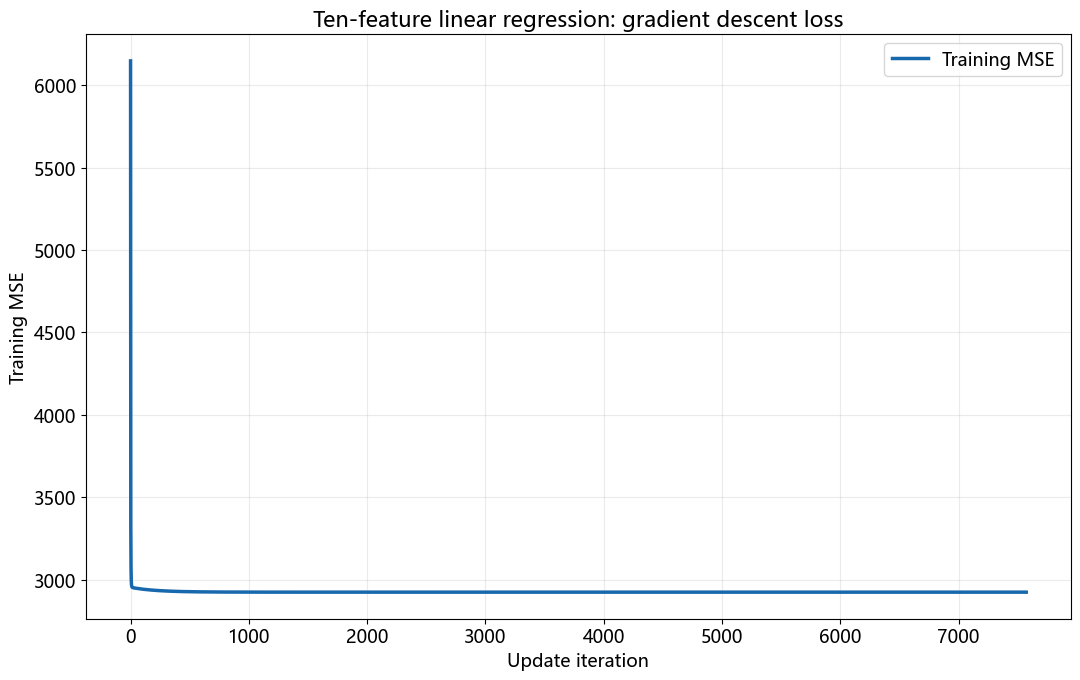

In [24]:
if RUN_OPTIONAL:
    plt.figure(figsize=(11, 7))
    plt.plot(np.arange(len(history)), history, lw=2.5, color='#1768ac', label='Training MSE')
    plt.xlabel('Update iteration')
    plt.ylabel('Training MSE')
    plt.title('Ten-feature linear regression: gradient descent loss')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print('Task 8 loss plot skipped (optional)')

## 报告与提交（每生一份）

实验报告Word + 代码.py或.ipynb，基本名统一`学号+姓名_实验1`。
提交方式、截止期限**另行通知**。报告必做任务1—5，4a和4b不得遗漏；选做不加分。
报告包含环境、数据与预处理、模型、训练/测试六指标、4a系数与预测核对、4b类及截距/系数/预测allclose、
两张有标题坐标轴的图和自己的中文解释、问题处理与总结。

### 评分：课堂表现5分 + 报告5分

- 课堂表现：按出勤和完成度给分。
- 报告规范1.5分：结构、个人信息、命名、图表规范。
- 代码质量与核对2分：可复现、核心代码正确、尺度一致、手动类与sklearn核对证据。
- 分析图表1.5分：三指标解释、两图解读、局限与问题分析。

### 正式提交前：完整性检查

- [ ] 任务1—5全部完成，包括4a和4b；不只交课内检查。
- [ ] None空位补齐，保护断言保留，未完成不冒充完成。
- [ ] 两图标题/坐标轴清楚，BMI尺度正确，配自己的中文解读。
- [ ] 选做未做保持False；补齐必做后重启全部运行，保存自己的真实输出。
- [ ] Word与代码同名，每生一份，按后续通知提交。